# Recommendation detection: model comparison

Classify Digikala comments as `not_recommended` (0) or `recommended` (1). The ambiguous `no_idea` label is excluded from this binary experiment and remains in the source data for later hybrid-system analysis.

This notebook uses one sampled dataset, one stratified train/test split, and the same five training folds to compare TF-IDF, fastText, and frozen ParsBERT. Select models by training CV macro-F1. The test results are exploratory because this test set has already been examined during development.


In [2]:
from pathlib import Path
import pandas as pd

RANDOM_STATE = 18
SAMPLES_PER_CLASS = 5000  # Keep the first experiment affordable; applied after raw deduplication.
TEST_SIZE = 0.2
CV_FOLDS = 5
N_JOBS = 2  # Limit concurrent fits to control memory use.
LABELS = {"not_recommended": 0, "recommended": 1}
LABEL_NAMES = {value: key for key, value in LABELS.items()}

PROJECT_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents)
     if (root / "data" / "digikala-comments.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the project root or one of its subdirectories.")

# Load only the columns needed for this experiment.
df = pd.read_csv(
    PROJECT_ROOT / "data" / "digikala-comments.csv",
    usecols=["body", "recommendation_status"],
)
df["source_row"] = df.index
print("Source rows:", len(df))
display(df["recommendation_status"].value_counts(dropna=False))

Source rows: 6156289


recommendation_status
recommended        4162839
NaN                 894426
no_idea             594121
not_recommended     504903
Name: count, dtype: int64

## 1. Load and audit the data

Remove blank comments and unsupported labels. Keep one copy of identical texts with a consistent label; remove every copy when identical texts have conflicting labels. Report the changes before sampling.


In [3]:
no_idea_mask = df["recommendation_status"].eq("no_idea")
print("Excluded no_idea rows:", no_idea_mask.sum())
df = df.loc[~no_idea_mask].copy()
df["recommendation_status"] = df["recommendation_status"].map(LABELS)
print("Missing or unsupported labels:", df["recommendation_status"].isna().sum())
print("Missing bodies:", df["body"].isna().sum())
df = df.dropna(subset=["body", "recommendation_status"]).copy()
df["body"] = df["body"].str.strip()
print("Blank bodies:", df["body"].eq("").sum())
df = df.loc[df["body"].ne("")].copy()
df["recommendation_status"] = df["recommendation_status"].astype(int)


def audit_and_deduplicate(frame, text_column, stage):
    duplicate_mask = frame.duplicated(text_column, keep=False)
    label_counts = (
        frame[[text_column, "recommendation_status"]]
        .drop_duplicates()
        [text_column].value_counts()
    )
    conflicting_texts = label_counts.index[label_counts.gt(1)]
    conflict_mask = frame[text_column].isin(conflicting_texts)
    consistent = frame.loc[~conflict_mask]
    cleaned = consistent.drop_duplicates(text_column, keep="first").copy()
    report = pd.Series({
        "input_rows": len(frame),
        "rows_in_duplicate_groups": int(duplicate_mask.sum()),
        "duplicate_text_groups": int(frame.loc[duplicate_mask, text_column].nunique()),
        "conflicting_text_groups": len(conflicting_texts),
        "conflicting_rows_removed": int(conflict_mask.sum()),
        "same_label_copies_removed": len(consistent) - len(cleaned),
        "remaining_rows": len(cleaned),
    }, name=stage)
    display(report)
    return cleaned, report


df, raw_duplicate_report = audit_and_deduplicate(df, "body", "full_dataset_raw_text")
display(df["recommendation_status"].map(LABEL_NAMES).value_counts())

Excluded no_idea rows: 594121
Missing or unsupported labels: 894426
Missing bodies: 594
Blank bodies: 0


input_rows                   4667284
rows_in_duplicate_groups     1735483
duplicate_text_groups         153274
conflicting_text_groups         6479
conflicting_rows_removed      848434
same_label_copies_removed     740254
remaining_rows               3078596
Name: full_dataset_raw_text, dtype: int64

recommendation_status
recommended        2642629
not_recommended     435967
Name: count, dtype: int64

### Reproducible sample

Sample up to 5,000 unique comments from each class using the fixed seed. This balances the experiment approximately; the resulting class distribution does not represent the original dataset.


In [4]:
sampled = pd.concat([
    df.loc[df["recommendation_status"].eq(label)].sample(
        n=min(SAMPLES_PER_CLASS, int(df["recommendation_status"].eq(label).sum())),
        random_state=RANDOM_STATE,
    )
    for label in LABELS.values()
]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
# Release the full dataset before NLP preprocessing and cross-validation.
del df
df = sampled
del sampled
print("Sampled rows:", len(df))
display(df["recommendation_status"].map(LABEL_NAMES).value_counts())

Sampled rows: 10000


recommendation_status
not_recommended    5000
recommended        5000
Name: count, dtype: int64

### Text preparation and duplicate check

For TF-IDF, normalize and tokenize with Hazm. Keep known verb forms unchanged to preserve negation; lemmatize other tokens. Retain stopwords, one-letter tokens, and half-spaces; emoji are not explicitly removed. Remove empty texts and collisions introduced by preprocessing before splitting the data. The TF-IDF vocabulary is learned inside each CV training fold.


In [5]:
import string
import hazm

normalizer = hazm.Normalizer()
word_tokenizer = hazm.WordTokenizer()
lemmatizer = hazm.Lemmatizer()


def remove_chars(text, chars):
    for char in chars:
        text = text.replace(char, " ")
    return text


def preprocess(text):
    if not isinstance(text, str):
        return None
    text = remove_chars(text.lower(), string.punctuation + "؟،")
    text = normalizer.normalize(text).replace("آ", "ا")
    # Preserve the half-space so negated verbs remain intact during tokenization.
    text = remove_chars(text, "۰۱۲۳۴۵۶۷۸۹")
    tokens = [
        token if token in lemmatizer.verbs
        else lemmatizer.lemmatize(token).split("#")[0]
        for token in word_tokenizer.tokenize(text)
    ]
    return " ".join(tokens) if tokens else None


df["processed_body"] = df["body"].apply(preprocess)
print("Empty after preprocessing:", df["processed_body"].isna().sum())
df = df.dropna(subset=["processed_body"]).copy()
df, processed_duplicate_report = audit_and_deduplicate(
    df, "processed_body", "sample_processed_text"
)
df = df.reset_index(drop=True)
duplicate_report = pd.concat([raw_duplicate_report, processed_duplicate_report], axis=1)
display(df[["body", "processed_body", "recommendation_status"]].head())

Empty after preprocessing: 1


input_rows                   9999
rows_in_duplicate_groups        8
duplicate_text_groups           3
conflicting_text_groups         0
conflicting_rows_removed        0
same_label_copies_removed       5
remaining_rows               9994
Name: sample_processed_text, dtype: int64

,body,processed_body,recommendation_status
0,نصف موهام ریخت همون لطیفس انگار فقط بسته بندیش...,نصف موه ریخت همون لطیفس انگار فقط بسته بندیشو ...,0
1,زبر بود کاش سافت داشت,زبر بود کاش ساف داشت,1
2,قشنگ و اندازه خوب,قشنگ و اندازه خوب,1
3,سلام دماسنج خوبیه و دقت خوبی داره البته من برا...,سلام دماسنج خوبیه و دقت خوبی داره البته من برا...,1
4,بوشو دوست نداشتم و اینکه چرب میکنه موها رو,بوشو دوست نداشتم و اینکه چرب میکنه مو رو,0


## 2. Freeze the train/test split

Reserve 20% of the cleaned sample for test and use five stratified folds on train. All three experiments below use these same rows and labels. This text-level split does not measure generalization to unseen products or future comments.


In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold

if set(df["recommendation_status"]) != set(LABELS.values()):
    raise ValueError("Both recommendation classes must remain after cleaning.")

X_train, X_test, y_train, y_test = train_test_split(
    df["processed_body"], df["recommendation_status"],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["recommendation_status"],
)
assert set(X_train).isdisjoint(set(X_test)), "Duplicate text crosses train/test."
if y_train.value_counts().min() < CV_FOLDS:
    raise ValueError("Not enough training examples per class for cross-validation.")

split_counts = pd.DataFrame({
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
}).reindex(list(LABELS.values())).rename(index=LABEL_NAMES)
display(split_counts)
print("Train:", len(X_train), "| Reserved test:", len(X_test))

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

,train,test
recommendation_status,,
not_recommended,4000,1000
recommended,3995,999


Train: 7995 | Reserved test: 1999


## 3. TF-IDF: word and character features

Compare word TF-IDF with a combination of word and 3–5 character features (`char_wb`). GridSearchCV tunes the word branch and five compatible classifiers using training folds only. Rank candidates by macro-F1 and record accuracy as a secondary metric.


In [7]:
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import GridSearchCV, ParameterGrid
from joblib import parallel_config

pipeline = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2), max_df=0.9)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

feature_grids = [
    {
        "vectorizer": [TfidfVectorizer(ngram_range=(1, 2), max_df=0.9)],
        "vectorizer__min_df": [2, 5],
        "vectorizer__sublinear_tf": [False, True],
    },
    {
        "vectorizer": [FeatureUnion([
            ("word", TfidfVectorizer(ngram_range=(1, 2), max_df=0.9)),
            ("char", TfidfVectorizer(
                analyzer="char_wb", ngram_range=(3, 5),
                min_df=2, sublinear_tf=True,
            )),
        ])],
        "vectorizer__word__min_df": [2, 5],
        "vectorizer__word__sublinear_tf": [False, True],
    },
]
model_grids = [
    {
        "model": [LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
    },
    {
        "model": [LinearSVC(max_iter=5000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
    },
    {
        "model": [ComplementNB()],
        "model__alpha": [0.1, 1.0, 10.0],
    },
    {
        "model": [RidgeClassifier()],
        "model__alpha": [0.1, 1.0, 10.0],
    },
    {
        "model": [SGDClassifier(loss="log_loss", max_iter=2000, random_state=RANDOM_STATE)],
        "model__alpha": [1e-5, 1e-4, 1e-3],
    },
]
param_grid = [
    {**feature_grid, **model_grid}
    for feature_grid in feature_grids
    for model_grid in model_grids
]

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring={"macro_f1": "f1_macro", "accuracy": "accuracy"},
    refit="macro_f1",
    cv=cv,
    n_jobs=N_JOBS,
    pre_dispatch=N_JOBS,
    error_score="raise",
    return_train_score=True,
    verbose=1,
)
print("Candidates:", len(list(ParameterGrid(param_grid))))
# Avoid CPU oversubscription when several fits run in parallel.
with parallel_config(backend="loky", inner_max_num_threads=1):
    grid.fit(X_train, y_train)


Candidates: 120
Fitting 5 folds for each of 120 candidates, totalling 600 fits


### TF-IDF selection and test report

GridSearchCV refits its selected pipeline on all training rows. Inspect CV results first, then report its predictions on the reserved test rows. Do not tune this experiment using the test report.


In [8]:
cv_results = pd.DataFrame(grid.cv_results_)
cv_results["feature_name"] = cv_results["param_vectorizer"].map(
    lambda vectorizer: "word + char_wb" if isinstance(vectorizer, FeatureUnion) else "word only"
)
cv_results["model_name"] = cv_results["param_model"].map(lambda model: type(model).__name__)
cv_results = cv_results.sort_values("rank_test_macro_f1", kind="stable")
result_columns = [
    "feature_name", "model_name", "rank_test_macro_f1", "mean_test_macro_f1",
    "std_test_macro_f1", "mean_test_accuracy", "mean_train_macro_f1",
    "mean_fit_time", "params",
]
best_per_combination = cv_results.drop_duplicates(["feature_name", "model_name"])[result_columns]
display(best_per_combination)
display(cv_results[result_columns].head(10))

best_pipeline = grid.best_estimator_
best_params = grid.best_params_
print("Selected features:", "word + char_wb" if isinstance(best_pipeline.named_steps["vectorizer"], FeatureUnion) else "word only")
print("Selected model:", type(best_pipeline.named_steps["model"]).__name__)
print("Best training CV macro-F1:", grid.best_score_)
print("Best parameters:", best_params)
print("The held-out test set remains unused for model selection.")


,feature_name,model_name,rank_test_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,mean_fit_time,params
72,word + char_wb,LinearSVC,1,0.892787,0.004902,0.892808,0.957783,0.896003,"{'model': LinearSVC(max_iter=5000, random_stat..."
112,word + char_wb,SGDClassifier,4,0.891290,0.006945,0.891307,0.966602,0.958277,"{'model': SGDClassifier(loss='log_loss', max_i..."
64,word + char_wb,LogisticRegression,8,0.890786,0.005544,0.890807,0.955657,0.994549,"{'model': LogisticRegression(max_iter=2000, ra..."
105,word + char_wb,RidgeClassifier,10,0.890520,0.007062,0.890557,0.942708,0.984171,"{'model': RidgeClassifier(), 'model__alpha': 1..."
53,word only,SGDClassifier,19,0.886404,0.004703,0.886429,0.957127,0.233369,"{'model': SGDClassifier(loss='log_loss', max_i..."
13,word only,LinearSVC,20,0.886271,0.005195,0.886304,0.946335,0.222999,"{'model': LinearSVC(max_iter=5000, random_stat..."
4,word only,LogisticRegression,26,0.884900,0.005816,0.884928,0.944178,0.245157,"{'model': LogisticRegression(max_iter=2000, ra..."
41,word only,RidgeClassifier,29,0.884540,0.004927,0.884553,0.986585,0.227406,"{'model': RidgeClassifier(), 'model__alpha': 1..."
28,word only,ComplementNB,30,0.884530,0.007445,0.884553,0.947153,0.205838,"{'model': ComplementNB(), 'model__alpha': 1.0,..."
91,word + char_wb,ComplementNB,67,0.878032,0.007729,0.878049,0.914382,0.857515,"{'model': ComplementNB(), 'model__alpha': 1.0,..."


,feature_name,model_name,rank_test_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,mean_fit_time,params
72,word + char_wb,LinearSVC,1,0.892787,0.004902,0.892808,0.957783,0.896003,"{'model': LinearSVC(max_iter=5000, random_stat..."
73,word + char_wb,LinearSVC,2,0.891910,0.005287,0.891932,0.957846,0.900386,"{'model': LinearSVC(max_iter=5000, random_stat..."
74,word + char_wb,LinearSVC,3,0.891291,0.005488,0.891307,0.951403,0.863900,"{'model': LinearSVC(max_iter=5000, random_stat..."
112,word + char_wb,SGDClassifier,4,0.891290,0.006945,0.891307,0.966602,0.958277,"{'model': SGDClassifier(loss='log_loss', max_i..."
113,word + char_wb,SGDClassifier,5,0.890913,0.006836,0.890932,0.967228,0.982204,"{'model': SGDClassifier(loss='log_loss', max_i..."
75,word + char_wb,LinearSVC,6,0.890913,0.005691,0.890932,0.951341,0.926927,"{'model': LinearSVC(max_iter=5000, random_stat..."
115,word + char_wb,SGDClassifier,7,0.890797,0.007356,0.890807,0.959691,0.950081,"{'model': SGDClassifier(loss='log_loss', max_i..."
64,word + char_wb,LogisticRegression,8,0.890786,0.005544,0.890807,0.955657,0.994549,"{'model': LogisticRegression(max_iter=2000, ra..."
65,word + char_wb,LogisticRegression,9,0.890784,0.005784,0.890807,0.955689,0.981976,"{'model': LogisticRegression(max_iter=2000, ra..."
105,word + char_wb,RidgeClassifier,10,0.890520,0.007062,0.890557,0.942708,0.984171,"{'model': RidgeClassifier(), 'model__alpha': 1..."


Selected features: word + char_wb
Selected model: LinearSVC
Best training CV macro-F1: 0.8927867920459054
Best parameters: {'model': LinearSVC(max_iter=5000, random_state=18), 'model__C': 0.1, 'vectorizer': FeatureUnion(transformer_list=[('word',
                                TfidfVectorizer(max_df=0.9,
                                                ngram_range=(1, 2))),
                               ('char',
                                TfidfVectorizer(analyzer='char_wb', min_df=2,
                                                ngram_range=(3, 5),
                                                sublinear_tf=True))]), 'vectorizer__word__min_df': 2, 'vectorizer__word__sublinear_tf': False}
The held-out test set remains unused for model selection.


Held-out test classification report:
                 precision    recall  f1-score   support

not_recommended      0.903     0.914     0.909      1000
    recommended      0.913     0.902     0.907       999

       accuracy                          0.908      1999
      macro avg      0.908     0.908     0.908      1999
   weighted avg      0.908     0.908     0.908      1999



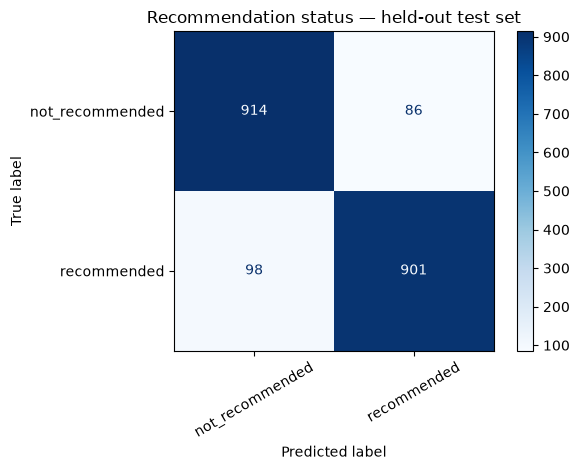

In [9]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Evaluate the model selected on training folds once on the reserved test set.
class_ids = list(LABEL_NAMES)
class_names = [LABEL_NAMES[class_id] for class_id in class_ids]
y_pred = best_pipeline.predict(X_test)

print("Held-out test classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    digits=3,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=class_ids,
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=30,
)
plt.title("Recommendation status — held-out test set")
plt.tight_layout()
plt.show()


## 4. Shared light normalization

fastText and ParsBERT use the same original comments after lowercasing, Persian normalization, punctuation and digit removal, and whitespace cleanup. They do not use the lemmatized TF-IDF text. Train/test membership and labels remain unchanged.


In [10]:
def preprocess_light(text):
    if not isinstance(text, str):
        return None
    text = remove_chars(text.lower(), string.punctuation + "؟،")
    text = normalizer.normalize(text).replace("آ", "ا")
    text = remove_chars(text, "۰۱۲۳۴۵۶۷۸۹")
    return " ".join(text.split()) or None


X_train_light = df.loc[X_train.index, "body"].apply(preprocess_light)
X_test_light = df.loc[X_test.index, "body"].apply(preprocess_light)
if X_train_light.isna().any() or X_test_light.isna().any():
    raise ValueError("An empty comment appeared after light normalization.")
assert X_train_light.index.equals(y_train.index)
assert X_test_light.index.equals(y_test.index)


## 5. fastText

This section needs `fasttext-wheel==0.9.2` on Windows with Python 3.12; import it as `fasttext`. Search word n-grams, optional character n-grams, learning rate, and epochs on the same five training folds. Train the selected configuration on all training rows and report its test result. fastText training writes temporary files that are removed automatically.


In [11]:
import fasttext
import tempfile
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import ParameterGrid

FASTTEXT_DIM = 50
FASTTEXT_BUCKET = 100_000
FASTTEXT_THREADS = 2
FASTTEXT_FIXED = {
    "dim": FASTTEXT_DIM,
    "bucket": FASTTEXT_BUCKET,
    "thread": FASTTEXT_THREADS,
    "loss": "softmax",
    "verbose": 0,
}
FASTTEXT_PARAM_GRID = [
    {"wordNgrams": [1, 2], "minn": [0], "maxn": [0],
     "epoch": [10, 25], "lr": [0.1, 0.5]},
    {"wordNgrams": [1, 2], "minn": [3], "maxn": [5],
     "epoch": [10, 25], "lr": [0.1, 0.5]},
]
FASTTEXT_PARAM_KEYS = ("wordNgrams", "minn", "maxn", "epoch", "lr")


def fasttext_line(text):
    # fastText expects one sample per line; collapse embedded whitespace.
    return " ".join(str(text).split())


# Reuse the shared light-normalized comments; the old fastText preprocessing is unchanged.
X_train_fasttext = X_train_light
X_test_fasttext = X_test_light


def write_fasttext_data(path, texts, labels):
    with Path(path).open("w", encoding="utf-8", newline="\n") as output:
        for text, label in zip(texts, labels, strict=True):
            output.write(f"__label__{LABEL_NAMES[int(label)]} {fasttext_line(text)}\n")


def predict_fasttext(model, texts):
    lines = [fasttext_line(text) for text in texts]
    predicted_labels, _ = model.predict(lines, k=1)
    return [LABELS[item[0].removeprefix("__label__")]
            for item in predicted_labels]


def fasttext_cv_search(texts, labels):
    """Search configurations using only training rows and the existing CV folds."""
    records = []
    folds = list(cv.split(texts, labels))
    configurations = list(ParameterGrid(FASTTEXT_PARAM_GRID))
    with tempfile.TemporaryDirectory(prefix="vazheh_fasttext_cv_") as folder:
        training_file = Path(folder) / "train.txt"
        for number, params in enumerate(configurations, start=1):
            fold_f1, fold_accuracy = [], []
            for train_pos, valid_pos in folds:
                write_fasttext_data(
                    training_file, texts.iloc[train_pos], labels.iloc[train_pos]
                )
                model = fasttext.train_supervised(
                    input=str(training_file), **FASTTEXT_FIXED, **params
                )
                predicted = predict_fasttext(model, texts.iloc[valid_pos])
                actual = labels.iloc[valid_pos]
                fold_f1.append(f1_score(actual, predicted, average="macro"))
                fold_accuracy.append(accuracy_score(actual, predicted))
                del model
            records.append({
                **params,
                "mean_cv_macro_f1": sum(fold_f1) / len(fold_f1),
                "std_cv_macro_f1": pd.Series(fold_f1).std(ddof=0),
                "mean_cv_accuracy": sum(fold_accuracy) / len(fold_accuracy),
            })
            print(f"fastText configuration {number}/{len(configurations)} complete")
    return (pd.DataFrame(records)
            .sort_values(["mean_cv_macro_f1", "std_cv_macro_f1"],
                         ascending=[False, True])
            .reset_index(drop=True))


def fit_fasttext_on_all_train(texts, labels, params):
    with tempfile.TemporaryDirectory(prefix="vazheh_fasttext_final_") as folder:
        training_file = Path(folder) / "train.txt"
        write_fasttext_data(training_file, texts, labels)
        return fasttext.train_supervised(
            input=str(training_file), **FASTTEXT_FIXED, **params
        )

In [12]:
# Search 16 configurations × 5 training folds = 80 fastText fits.
fasttext_cv_results = fasttext_cv_search(X_train_fasttext, y_train)
display(fasttext_cv_results)
best_fasttext_params = {
    key: (int(fasttext_cv_results.loc[0, key]) if key != "lr"
          else float(fasttext_cv_results.loc[0, key]))
    for key in FASTTEXT_PARAM_KEYS
}
print("Selected fastText parameters:", best_fasttext_params)
print("Best fastText training CV macro-F1:", fasttext_cv_results.loc[0, "mean_cv_macro_f1"])

fastText configuration 1/16 complete
fastText configuration 2/16 complete
fastText configuration 3/16 complete
fastText configuration 4/16 complete
fastText configuration 5/16 complete
fastText configuration 6/16 complete
fastText configuration 7/16 complete
fastText configuration 8/16 complete
fastText configuration 9/16 complete
fastText configuration 10/16 complete
fastText configuration 11/16 complete
fastText configuration 12/16 complete
fastText configuration 13/16 complete
fastText configuration 14/16 complete
fastText configuration 15/16 complete
fastText configuration 16/16 complete


,epoch,lr,maxn,minn,wordNgrams,mean_cv_macro_f1,std_cv_macro_f1,mean_cv_accuracy
0,10,0.1,5,3,2,0.881641,0.006599,0.881676
1,25,0.1,0,0,2,0.880036,0.005322,0.880050
2,10,0.1,5,3,1,0.879644,0.006832,0.879675
3,10,0.1,0,0,2,0.878286,0.006237,0.878299
4,25,0.1,5,3,2,0.878156,0.007340,0.878174
5,10,0.5,0,0,2,0.876037,0.004516,0.876048
6,10,0.5,5,3,2,0.874028,0.005558,0.874046
7,25,0.5,0,0,2,0.874023,0.005025,0.874046
8,25,0.5,5,3,2,0.872528,0.006602,0.872545
9,25,0.1,5,3,1,0.872153,0.007764,0.872170


Selected fastText parameters: {'wordNgrams': 2, 'minn': 3, 'maxn': 5, 'epoch': 10, 'lr': 0.1}
Best fastText training CV macro-F1: 0.8816410424037358


fastText test classification report:
                 precision    recall  f1-score   support

not_recommended      0.892     0.911     0.902      1000
    recommended      0.909     0.890     0.899       999

       accuracy                          0.900      1999
      macro avg      0.901     0.900     0.900      1999
   weighted avg      0.901     0.900     0.900      1999



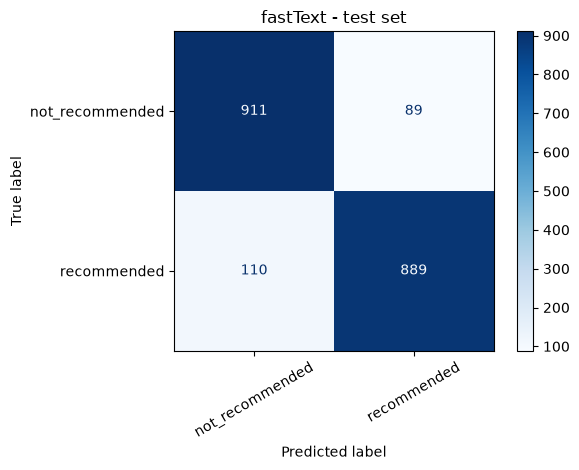

In [13]:
# Fit the selected fastText configuration on all training rows.
fasttext_model = fit_fasttext_on_all_train(X_train_fasttext, y_train, best_fasttext_params)
fasttext_test_pred = predict_fasttext(fasttext_model, X_test_fasttext)

print("fastText test classification report:")
print(classification_report(
    y_test, fasttext_test_pred,
    labels=list(LABEL_NAMES),
    target_names=[LABEL_NAMES[label] for label in LABEL_NAMES],
    digits=3,
    zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test, fasttext_test_pred,
    labels=list(LABEL_NAMES),
    display_labels=[LABEL_NAMES[label] for label in LABEL_NAMES],
    cmap="Blues", values_format="d", xticks_rotation=30,
)
plt.title("fastText - test set")
plt.tight_layout()
plt.show()


## 6. Frozen ParsBERT

Use [`HooshvareLab/bert-base-parsbert-uncased`](https://huggingface.co/HooshvareLab/bert-base-parsbert-uncased) as a fixed encoder; this section needs `torch` and `transformers`. Mean-pool token vectors while excluding padding, and truncate at 128 tokens. Encode training comments once, then compare LogisticRegression, LinearSVC, RidgeClassifier, and RBF SVC on the same five folds. The encoder is not fine-tuned.


In [14]:
import numpy as np
import torch
from transformers import AutoModel, AutoTokenizer

BERT_MODEL_ID = "HooshvareLab/bert-base-parsbert-uncased"
BERT_MAX_LENGTH = 128
BERT_BATCH_SIZE = 16 if torch.cuda.is_available() else 8
bert_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_ID)
bert_encoder = AutoModel.from_pretrained(BERT_MODEL_ID).to(bert_device)
bert_encoder.eval()


@torch.inference_mode()
def encode_comments_bert(texts):
    vectors = []
    texts = texts.tolist()
    for start in range(0, len(texts), BERT_BATCH_SIZE):
        batch = texts[start:start + BERT_BATCH_SIZE]
        tokens = bert_tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=BERT_MAX_LENGTH,
            return_tensors="pt",
        )
        tokens = {name: value.to(bert_device) for name, value in tokens.items()}
        token_vectors = bert_encoder(**tokens).last_hidden_state
        attention_mask = tokens["attention_mask"].unsqueeze(-1)
        pooled = (token_vectors * attention_mask).sum(dim=1) / attention_mask.sum(dim=1).clamp(min=1)
        vectors.append(pooled.cpu().numpy())
        if (start // BERT_BATCH_SIZE + 1) % 50 == 0 or start + len(batch) == len(texts):
            print(f"Encoded {start + len(batch)}/{len(texts)} comments")
    return np.vstack(vectors)


X_train_bert = encode_comments_bert(X_train_light)
print("ParsBERT device:", bert_device)
print("Train embeddings:", X_train_bert.shape)


f:\Roham\projects\Web\Django\vazheh-kav\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: d13a8603-7f8b-42dc-972f-eae29f7cb87e)')' thrown while requesting HEAD https://huggingface.co/HooshvareLab/bert-base-parsbert-uncased/resolve/main/tokenizer_config.json
Retrying in 1s [Retry 1/5].
'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: 40f2b3ae-610c-47c9-99af-e096ef806d18)')' thrown while requesting HEAD https://huggingface.co/HooshvareLab/bert-base-parsbert-uncased/resolve/main/tokenizer_config.json
Retrying in 2s [Retry 2/5].
'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. 

Encoded 800/7995 comments
Encoded 1600/7995 comments
Encoded 2400/7995 comments
Encoded 3200/7995 comments
Encoded 4000/7995 comments
Encoded 4800/7995 comments
Encoded 5600/7995 comments
Encoded 6400/7995 comments
Encoded 7200/7995 comments
Encoded 7995/7995 comments
ParsBERT device: cuda
Train embeddings: (7995, 768)


In [15]:
from sklearn.preprocessing import Normalizer
from sklearn.svm import SVC

bert_pipeline = Pipeline([
    ("normalize", Normalizer()),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
bert_param_grid = [
    {
        "model": [LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
    },
    {
        "model": [LinearSVC(max_iter=5000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
    },
    {
        "model": [RidgeClassifier()],
        "model__alpha": [0.1, 1.0, 10.0],
    },
    {
        "model": [SVC(kernel="rbf", gamma="scale")],
        "model__C": [1.0, 10.0],
    },
]
bert_grid = GridSearchCV(
    estimator=bert_pipeline,
    param_grid=bert_param_grid,
    scoring={"macro_f1": "f1_macro", "accuracy": "accuracy"},
    refit="macro_f1",
    cv=cv,
    n_jobs=N_JOBS,
    pre_dispatch=N_JOBS,
    error_score="raise",
    return_train_score=True,
)
with parallel_config(backend="loky", inner_max_num_threads=1):
    bert_grid.fit(X_train_bert, y_train)

bert_cv_results = pd.DataFrame(bert_grid.cv_results_)
bert_cv_results["model_name"] = bert_cv_results["param_model"].map(
    lambda model: type(model).__name__
)
bert_cv_results = bert_cv_results.sort_values("rank_test_macro_f1", kind="stable")
display(bert_cv_results[[
    "model_name", "mean_test_macro_f1", "std_test_macro_f1",
    "mean_test_accuracy", "mean_train_macro_f1", "params",
]])
print("Best ParsBERT training CV macro-F1:", bert_grid.best_score_)
print("Best classifier parameters:", bert_grid.best_params_)


,model_name,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,params
9,SVC,0.876123,0.004574,0.876173,0.908069,"{'model': SVC(), 'model__C': 1.0}"
10,SVC,0.874787,0.005585,0.874797,0.985241,"{'model': SVC(), 'model__C': 10.0}"
4,LinearSVC,0.873003,0.007242,0.873046,0.894009,"{'model': LinearSVC(max_iter=5000, random_stat..."
7,RidgeClassifier,0.871351,0.007679,0.871420,0.888357,"{'model': RidgeClassifier(), 'model__alpha': 1.0}"
2,LogisticRegression,0.870629,0.006989,0.870669,0.889979,"{'model': LogisticRegression(max_iter=2000, ra..."
3,LinearSVC,0.869698,0.006355,0.869794,0.878545,"{'model': LinearSVC(max_iter=5000, random_stat..."
6,RidgeClassifier,0.869005,0.008392,0.869043,0.901636,"{'model': RidgeClassifier(), 'model__alpha': 0.1}"
1,LogisticRegression,0.868467,0.004854,0.868543,0.877719,"{'model': LogisticRegression(max_iter=2000, ra..."
5,LinearSVC,0.867134,0.004704,0.867167,0.911564,"{'model': LinearSVC(max_iter=5000, random_stat..."
8,RidgeClassifier,0.865659,0.006990,0.865791,0.871556,"{'model': RidgeClassifier(), 'model__alpha': 1..."


Best ParsBERT training CV macro-F1: 0.8761228352011395
Best classifier parameters: {'model': SVC(), 'model__C': 1.0}


Encoded 800/1999 comments
Encoded 1600/1999 comments
Encoded 1999/1999 comments
Frozen ParsBERT test classification report:
                 precision    recall  f1-score   support

not_recommended      0.887     0.908     0.897      1000
    recommended      0.906     0.884     0.895       999

       accuracy                          0.896      1999
      macro avg      0.896     0.896     0.896      1999
   weighted avg      0.896     0.896     0.896      1999



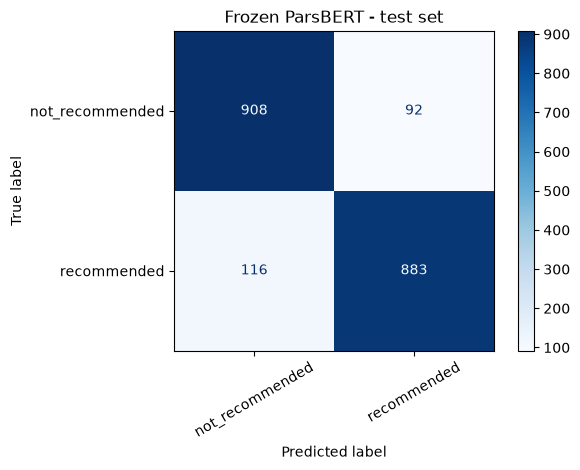

In [16]:
# Evaluate the classifier selected by training CV on the same test rows.
X_test_bert = encode_comments_bert(X_test_light)
bert_test_pred = bert_grid.predict(X_test_bert)

print("Frozen ParsBERT test classification report:")
print(classification_report(
    y_test, bert_test_pred,
    labels=list(LABEL_NAMES),
    target_names=[LABEL_NAMES[label] for label in LABEL_NAMES],
    digits=3,
    zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test, bert_test_pred,
    labels=list(LABEL_NAMES),
    display_labels=[LABEL_NAMES[label] for label in LABEL_NAMES],
    cmap="Blues", values_format="d", xticks_rotation=30,
)
plt.title("Frozen ParsBERT - test set")
plt.tight_layout()
plt.show()


## 7. Compare the three approaches

Show the selected model from each experiment on the same train folds and test rows. Choose the overall winner by training CV macro-F1; the test columns describe the saved development comparison and are not used for selection. Model export to Django is a separate step.


In [17]:
from sklearn.metrics import accuracy_score, f1_score

comparison = pd.DataFrame([
    {
        "approach": "TF-IDF",
        "selected_model": type(best_pipeline.named_steps["model"]).__name__,
        "cv_macro_f1": grid.best_score_,
        "test_macro_f1": f1_score(y_test, y_pred, average="macro"),
        "test_accuracy": accuracy_score(y_test, y_pred),
    },
    {
        "approach": "fastText",
        "selected_model": "fastText supervised",
        "cv_macro_f1": fasttext_cv_results.loc[0, "mean_cv_macro_f1"],
        "test_macro_f1": f1_score(y_test, fasttext_test_pred, average="macro"),
        "test_accuracy": accuracy_score(y_test, fasttext_test_pred),
    },
    {
        "approach": "Frozen ParsBERT",
        "selected_model": type(bert_grid.best_estimator_.named_steps["model"]).__name__,
        "cv_macro_f1": bert_grid.best_score_,
        "test_macro_f1": f1_score(y_test, bert_test_pred, average="macro"),
        "test_accuracy": accuracy_score(y_test, bert_test_pred),
    },
]).sort_values("cv_macro_f1", ascending=False, kind="stable").reset_index(drop=True)

display(comparison)
print("Selected by training CV macro-F1:", comparison.loc[0, "approach"])
print("Test scores are exploratory; the test set was viewed during development.")


,approach,selected_model,cv_macro_f1,test_macro_f1,test_accuracy
0,TF-IDF,LinearSVC,0.892787,0.907950,0.907954
1,fastText,fastText supervised,0.881641,0.900438,0.900450
2,Frozen ParsBERT,SVC,0.876123,0.895932,0.895948


Selected by training CV macro-F1: TF-IDF
Test scores are exploratory; the test set was viewed during development.


## 8. Calibrate the selected model's probabilities

The TF-IDF pipeline won by training CV macro-F1. Its LinearSVC classifier provides decision scores rather than probabilities. Fit sigmoid calibration from out-of-fold predictions on the training set, then refit the same pipeline on all training rows. The test set is used only for the report below, not to fit the calibrator or choose its method.

Compare accuracy and macro-F1 before and after calibration; calibration may change predicted labels. Report the Brier score and a reliability diagram for the calibrated probability of `recommended`. As the test set was examined during development, these numbers are exploratory.


In [18]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV

if comparison.loc[0, "approach"] != "TF-IDF":
    raise ValueError("This calibration section expects TF-IDF to win the CV comparison.")

calibrated_pipeline = CalibratedClassifierCV(
    estimator=clone(best_pipeline),
    method="sigmoid",
    cv=cv,
    ensemble=False,
    n_jobs=N_JOBS,
)
# Calibration uses out-of-fold training scores; the reserved test rows stay untouched.
with parallel_config(backend="loky", inner_max_num_threads=1):
    calibrated_pipeline.fit(X_train, y_train)

print("Calibrated model:", type(best_pipeline.named_steps["model"]).__name__)
print("Classes:", calibrated_pipeline.classes_)


Calibrated model: LinearSVC
Classes: [0 1]


,model,test_accuracy,test_macro_f1
0,Selected TF-IDF (before calibration),0.907954,0.907950
1,Selected TF-IDF (sigmoid calibrated),0.906453,0.906453


Final calibrated test accuracy: 0.9064532266133066
Final calibrated test macro-F1: 0.9064528520502455
Calibrated Brier score (lower is better): 0.06802413264020442
Calibrated classification report:
                 precision    recall  f1-score   support

not_recommended      0.905     0.908     0.907      1000
    recommended      0.908     0.905     0.906       999

       accuracy                          0.906      1999
      macro avg      0.906     0.906     0.906      1999
   weighted avg      0.906     0.906     0.906      1999



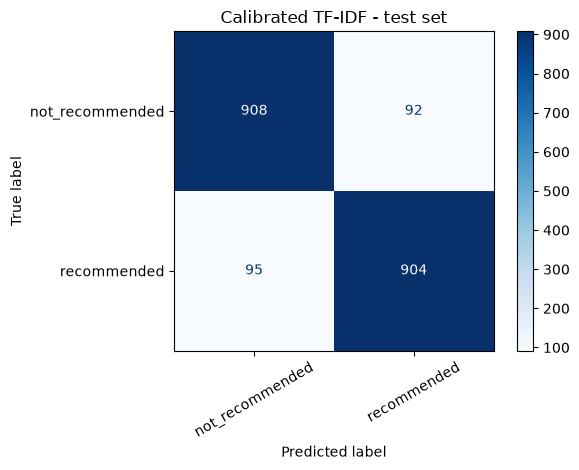

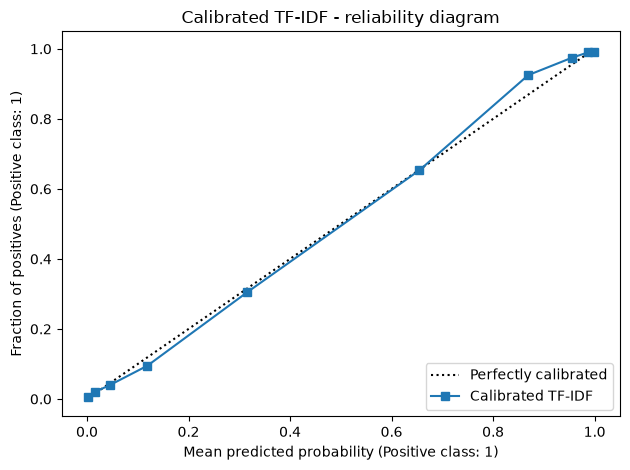

In [19]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

calibrated_pred = calibrated_pipeline.predict(X_test)
positive_label = LABELS["recommended"]
positive_index = list(calibrated_pipeline.classes_).index(positive_label)
recommended_probability = calibrated_pipeline.predict_proba(X_test)[:, positive_index]

final_scores = pd.DataFrame([
    {
        "model": "Selected TF-IDF (before calibration)",
        "test_accuracy": accuracy_score(y_test, y_pred),
        "test_macro_f1": f1_score(y_test, y_pred, average="macro"),
    },
    {
        "model": "Selected TF-IDF (sigmoid calibrated)",
        "test_accuracy": accuracy_score(y_test, calibrated_pred),
        "test_macro_f1": f1_score(y_test, calibrated_pred, average="macro"),
    },
])
display(final_scores)
print("Final calibrated test accuracy:", final_scores.loc[1, "test_accuracy"])
print("Final calibrated test macro-F1:", final_scores.loc[1, "test_macro_f1"])
print("Calibrated Brier score (lower is better):", brier_score_loss(
    y_test, recommended_probability, pos_label=positive_label,
))
print("Calibrated classification report:")
print(classification_report(
    y_test, calibrated_pred,
    labels=list(LABEL_NAMES),
    target_names=[LABEL_NAMES[label] for label in LABEL_NAMES],
    digits=3,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test, calibrated_pred,
    labels=list(LABEL_NAMES),
    display_labels=[LABEL_NAMES[label] for label in LABEL_NAMES],
    cmap="Blues", values_format="d", xticks_rotation=30,
)
plt.title("Calibrated TF-IDF - test set")
plt.tight_layout()
plt.show()

CalibrationDisplay.from_predictions(
    y_test, recommended_probability,
    n_bins=10, strategy="quantile", pos_label=positive_label,
    name="Calibrated TF-IDF",
)
plt.title("Calibrated TF-IDF - reliability diagram")
plt.tight_layout()
plt.show()


## 9. Save the calibrated model

Save the model selected above to Django's model directory. The saved estimator expects text prepared with this notebook's `preprocess` function; align Django's preprocessing before using it for application predictions.


In [20]:
import joblib

model_path = PROJECT_ROOT / "web" / "services" / "models" / "recommendation_detection_pipeline.joblib"
joblib.dump(calibrated_pipeline, model_path)
print("Saved calibrated model to:", model_path)


Saved calibrated model to: f:\Roham\projects\Web\Django\vazheh-kav\web\services\models\recommendation_detection_pipeline.joblib
